# Fitting SplineFlow and cSplineFlow to distribution functions

In this notebook, SplineFlow and cSplineFlow (neural spline flows with rational-quadratic spline coupling layers) learn
**analytically known distributions** from samples. Because the exact density is known, the quality of the fit can be verified
directly. A normalizing flow provides an **exact `log_prob`**, so the learned density itself can be compared with the exact one
(not only samples): density plots, log-likelihood on test data, and a Kullback-Leibler estimate `KL(p ‖ q)`.
The targets are the same as in `realnvp_crealnvp_distribution_fitting.ipynb`, so the results can be compared directly.

**Spline flows.** A SplineFlow is built like RealNVP from coupling layers, but every transformed dimension is mapped by a
monotonic **rational-quadratic spline** instead of an affine map `x · exp(s) + t`. The network predicts the `n_bins` bin widths,
bin heights and knot derivatives of the spline from the kept dimensions (and the condition). The spline acts on
`[-tail_bound, tail_bound]` and is the identity outside, so the data should lie (mostly) inside this interval.
A single spline coupling layer can bend a density much more strongly than an affine one (it can, for example, create several
modes in one step), so fewer coupling layers are needed. The price is a higher cost per layer.

| Section | Model | Target Distribution |
|---|---|---|
| 3 | SplineFlow | 2D-Gaussian-Mixture `p(x)` |
| 4 | SplineFlow | 3D-Gaussian-Velocity-Distribution `p(v)` (Magnitude: Maxwell-Distribution) |
| 5 | cSplineFlow | Maxwell-Distribution with temperature as condition `p(v \| T)` |
| 6 | SplineFlow | Influence of the number of coupling layers `n_coupling` and of the number of bins `n_bins` |
| 7 | SplineFlow / cSplineFlow | Invertibility, storage and loading |

Units: `m = k_B = 1`, so `σ² = T` and `v ~ N(0, T·I)`.

> **Disclaimer:** The models in this notebook are illustrative examples, not optimized results. Architectures, hyperparameters and training settings were chosen to keep the runtime short, not to reach maximum accuracy. The reported accuracies are therefore not the best achievable with this approach; there is most likely considerable room for improvement, e.g. through tuning of the number of coupling layers, number of bins, network size, learning rate (schedule), batch size and number of epochs.

> **Requirements:** `scipy` (exact densities, KS test) and `matplotlib`.


## 1. Setup

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from scipy import stats
from scipy.special import logsumexp

from neuraldist.generative_model.registry import build_model
import neuraldist.generative_model.splineflow  # Import registers "splineflow", "csplineflow" and "csplineflow_db"
from neuraldist.training import fit_model

tf.keras.utils.set_random_seed(0)
rng = np.random.default_rng(0)

# large batches and a higher learning rate keep the training in this notebook fast
FIT = dict(batch_size=512, learning_rate=2e-3)

I0000 00:00:1794856041.799353   45195 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794856041.847545   45195 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794856043.417477   45195 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 2. Helperfunctions

In [2]:
def plot_history(history, title):
    fig, ax = plt.subplots(figsize=(5, 2.8))
    ax.plot(history.history["loss"])
    ax.set(title=f"{title}: negative log-likelihood", xlabel="Epoch")
    fig.tight_layout()
    plt.show()


def ks_statistic(samples, cdf):
    """Kolmogorov-Smirnov-Distance between samples and exact CDF (0 = perfect)."""
    return stats.kstest(samples, cdf).statistic


def kl_estimate(logp_exact, logq_model):
    """Monte-Carlo estimate of KL(p || q) from samples x ~ p (0 = perfect)."""
    return float(np.mean(logp_exact - logq_model))

## 3. SplineFlow: 2D-Gaussian-Mixture

Three components with different weights and covariances. The exact density is the weighted sum of the individual densities.
The flow is trained on 30,000 samples and evaluated on **separate** test samples.

In [3]:
weights = np.array([0.3, 0.4, 0.3])
means = np.array([[-2.0, -1.0], [2.0, -1.0], [0.0, 2.0]])
covs = np.array([[[0.30, 0.15], [0.15, 0.25]],
                 [[0.40, -0.10], [-0.10, 0.20]],
                 [[0.15, 0.00], [0.00, 0.35]]])


def sample_mixture(n):
    comp = rng.choice(len(weights), size=n, p=weights)
    x = np.stack([rng.multivariate_normal(means[k], covs[k]) for k in comp])
    return x.astype("float32")


def mixture_logpdf(x):
    return logsumexp([np.log(w) + stats.multivariate_normal(m, c).logpdf(x)
                      for w, m, c in zip(weights, means, covs)], axis=0)


def mixture_marginal_cdf(x1):
    """CDF of the x₁ marginal distribution (mixture of 1D normal distributions)."""
    return sum(w * stats.norm(m[0], np.sqrt(c[0, 0])).cdf(x1) for w, m, c in zip(weights, means, covs))


x_gm = sample_mixture(30_000)
x_gm_test = sample_mixture(10_000)
print("Training data:", x_gm.shape, "| test data:", x_gm_test.shape)

Training data: (30000, 2) | test data: (10000, 2)


E0000 00:00:1794856047.227044   45195 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


{'loss': 2.5156}


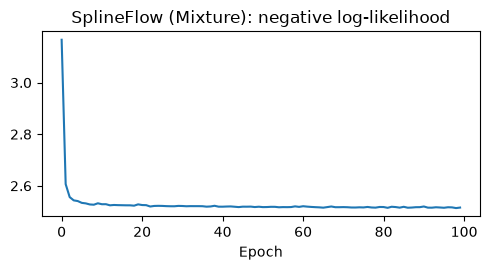

In [4]:
flow_gm = build_model("splineflow", x_dim=2, n_coupling=4)
history = fit_model(flow_gm, x_gm, epochs=100, **FIT)
print({k: round(v[-1], 4) for k, v in history.history.items()})
plot_history(history, "SplineFlow (Mixture)")

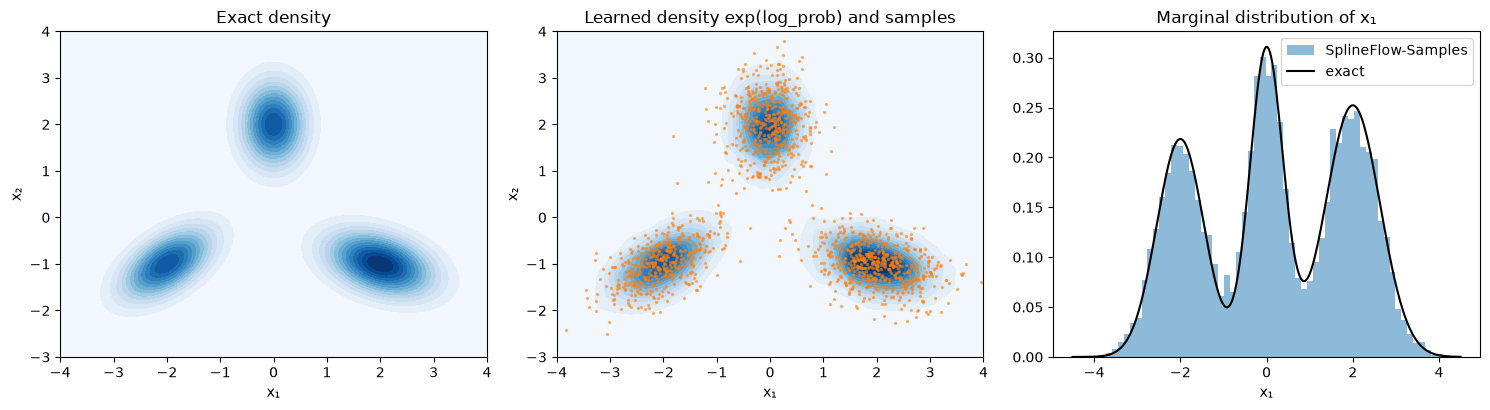

Mean log-likelihood on test data: exact -2.517 | SplineFlow -2.525
KL(p || q) estimate:              0.0075
KS distance of the x₁ marginal distribution: 0.016
Component weights ~ Percentage of samples near the mean values:
  Component 0: Samples 0.25 | Training data 0.25
  Component 1: Samples 0.32 | Training data 0.33
  Component 2: Samples 0.26 | Training data 0.26


In [5]:
# exact vs. learned density on a grid (log_prob of the flow, no sampling needed)
gx, gy = np.meshgrid(np.linspace(-4, 4, 200), np.linspace(-3, 4, 200))
xy_grid = np.dstack([gx, gy]).reshape(-1, 2).astype("float32")
density_exact = np.exp(mixture_logpdf(xy_grid)).reshape(gx.shape)
density_flow = np.exp(flow_gm.log_prob(xy_grid).numpy()).reshape(gx.shape)
levels = np.linspace(0, density_exact.max(), 16)

samples_gm = flow_gm.sample(10_000).numpy()          # unconditional: (n_samples, x_dim)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].contourf(gx, gy, density_exact, levels=levels, cmap="Blues")
axes[0].set(title="Exact density", xlabel="x₁", ylabel="x₂")
axes[1].contourf(gx, gy, np.minimum(density_flow, levels[-1]), levels=levels, cmap="Blues")  # clip peaks above the colour scale
axes[1].scatter(samples_gm[:1500, 0], samples_gm[:1500, 1], s=2, color="tab:orange", alpha=0.5)
axes[1].set(title="Learned density exp(log_prob) and samples", xlabel="x₁", ylabel="x₂", xlim=(-4, 4), ylim=(-3, 4))

grid1 = np.linspace(-4.5, 4.5, 300)
marg = sum(w * stats.norm(m[0], np.sqrt(c[0, 0])).pdf(grid1) for w, m, c in zip(weights, means, covs))
axes[2].hist(samples_gm[:, 0], bins=60, density=True, alpha=0.5, label="SplineFlow-Samples")
axes[2].plot(grid1, marg, "k", label="exact")
axes[2].set(title="Marginal distribution of x₁", xlabel="x₁")
axes[2].legend()
fig.tight_layout()
plt.show()

logp_exact = mixture_logpdf(x_gm_test)
logq_flow = flow_gm.log_prob(x_gm_test).numpy()
print(f"Mean log-likelihood on test data: exact {logp_exact.mean():.3f} | SplineFlow {logq_flow.mean():.3f}")
print(f"KL(p || q) estimate:              {kl_estimate(logp_exact, logq_flow):.4f}")
print(f"KS distance of the x₁ marginal distribution: {ks_statistic(samples_gm[:, 0], mixture_marginal_cdf):.3f}")
print("Component weights ~ Percentage of samples near the mean values:")
for k, m in enumerate(means):
    frac = (np.linalg.norm(samples_gm - m, axis=1) < 1.0).mean()
    frac_true = (np.linalg.norm(x_gm - m, axis=1) < 1.0).mean()
    print(f"  Component {k}: Samples {frac:.2f} | Training data {frac_true:.2f}")

**Observation:** The spline flow reproduces the three components with the correct weights and reaches KL ≈ 0.008 with only 4 coupling layers (RealNVP: KL ≈ 0.025 with 8 layers); the mean test log-likelihood (−2.525) is within 0.01 of the exact value. The low-density bridges between the components are much weaker than with RealNVP, but a few samples still fall between the modes: a flow is a continuous bijection of a single-peaked Gaussian, so it can make the bridges thin but never remove them completely.

## 4. SplineFlow: 3D-Gaussian-Velocity-Distribution

The velocity components are independently normally distributed, `v ~ N(0, σ²·I)`, where `σ = 1`.
The **magnitude** `|v|` is then Maxwell-distributed, `f(v) = √(2/π) · v²/σ³ · exp(-v²/2σ²)`.
The flow learns `v` (3D); in addition to the derived magnitude distribution, the **log-density of each test point**
is compared with the exact one.

{'loss': 4.2589}


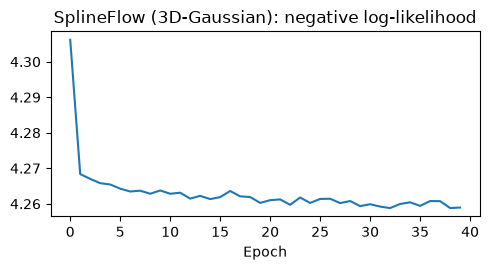

In [6]:
sigma = 1.0
v = rng.normal(0.0, sigma, size=(30_000, 3)).astype("float32")
v_test = rng.normal(0.0, sigma, size=(10_000, 3)).astype("float32")

flow_mw = build_model("splineflow", x_dim=3)
history = fit_model(flow_mw, v, epochs=40, **FIT)
print({k: round(val[-1], 4) for k, val in history.history.items()})
plot_history(history, "SplineFlow (3D-Gaussian)")

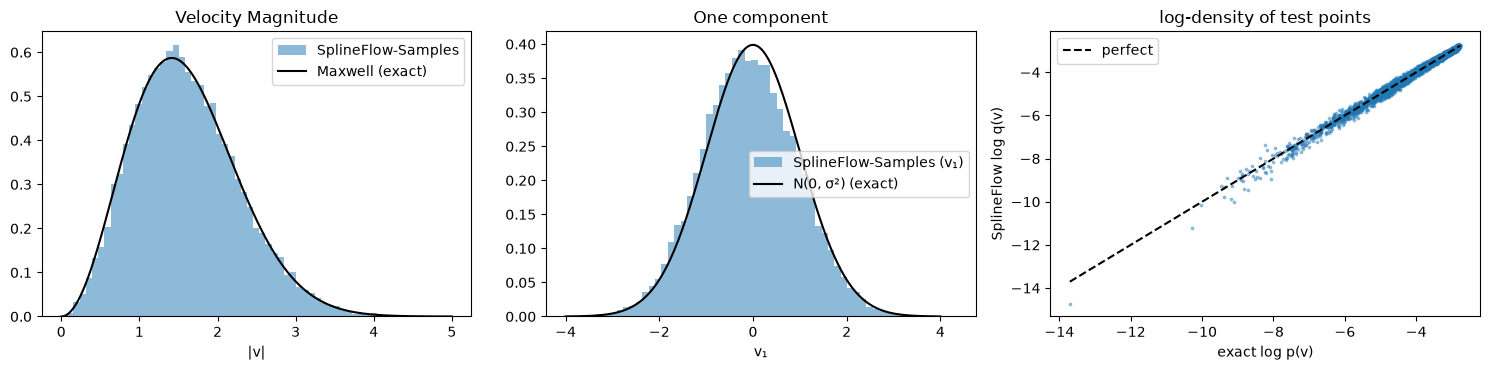

Standard deviation per component (target 1.0): [1.019 0.982 1.007]
Mean speed: Samples 1.603 | exact 1.596
KS distance of the magnitude:   0.008
KL(p || q) estimate:            0.0105


In [7]:
samples_v = flow_mw.sample(20_000).numpy()
speed = np.linalg.norm(samples_v, axis=1)

maxwell = stats.maxwell(scale=sigma)
vs = np.linspace(0, 5, 300)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(speed, bins=60, density=True, alpha=0.5, label="SplineFlow-Samples")
axes[0].plot(vs, maxwell.pdf(vs), "k", label="Maxwell (exact)")
axes[0].set(title="Velocity Magnitude", xlabel="|v|")
axes[0].legend()

v_axis = np.linspace(-4, 4, 300)
axes[1].hist(samples_v[:, 0], bins=60, density=True, alpha=0.5, label="SplineFlow-Samples (v₁)")
axes[1].plot(v_axis, stats.norm(0, sigma).pdf(v_axis), "k", label="N(0, σ²) (exact)")
axes[1].set(title="One component", xlabel="v₁")
axes[1].legend()

logp_exact = stats.multivariate_normal(np.zeros(3), sigma**2 * np.eye(3)).logpdf(v_test)
logq_flow = flow_mw.log_prob(v_test).numpy()
axes[2].scatter(logp_exact[:3000], logq_flow[:3000], s=3, alpha=0.4)
lims = [logp_exact.min(), logp_exact.max()]
axes[2].plot(lims, lims, "k--", label="perfect")
axes[2].set(title="log-density of test points", xlabel="exact log p(v)", ylabel="SplineFlow log q(v)")
axes[2].legend()
fig.tight_layout()
plt.show()

print(f"Standard deviation per component (target {sigma}):", samples_v.std(0).round(3))
print(f"Mean speed: Samples {speed.mean():.3f} | exact {maxwell.mean():.3f}")
print(f"KS distance of the magnitude:   {ks_statistic(speed, maxwell.cdf):.3f}")
print(f"KL(p || q) estimate:            {kl_estimate(logp_exact, logq_flow):.4f}")

**Observation:** The Gaussian velocity distribution is fitted well (KL ≈ 0.01, KS of the magnitude ≈ 0.008, widths within 2 %), but slightly worse than with RealNVP (KL ≈ 0.003). The target is the prior itself, so the ideal flow is the identity: an affine coupling layer represents it exactly, whereas the more flexible splines pick up a little sampling noise of the training data.

## 5. cSplineFlow: Temperature dependent Maxwell Distribution

Now the temperature is the condition `c = T ∈ [0.5, 2]`, and `v | T ~ N(0, T·I)` holds.
The model is supposed to learn a **single** distribution that scales correctly with `T`.

The dataset provides `(v, T)` pairs; `build_model("csplineflow", ..., cond_dim=1)` builds the conditional model.
Every spline network receives the temperature as additional input.

{'loss': 4.4724}


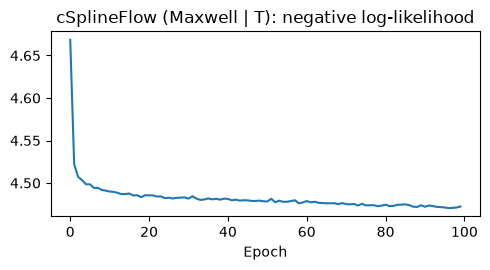

In [8]:
n = 30_000
T_train = rng.uniform(0.5, 2.0, size=(n, 1)).astype("float32")
v_train = (rng.standard_normal((n, 3)) * np.sqrt(T_train)).astype("float32")

csplineflow = build_model("csplineflow", x_dim=3, cond_dim=1)
history = fit_model(csplineflow, v_train, T_train, epochs=100, **FIT)
print({k: round(val[-1], 4) for k, val in history.history.items()})
plot_history(history, "cSplineFlow (Maxwell | T)")

### Conditional Sampling and Conditional Density for multiple temperatures

`sample(n_samples, cond)` where `cond` is of the form `(B, 1)` returns `(B, n_samples, 3)`: `n_samples` samples **per temperature**.
`log_prob(v, T)` evaluates the conditional density `log q(v | T)`.

cond: (3, 1) -> samples: (3, 20000, 3)


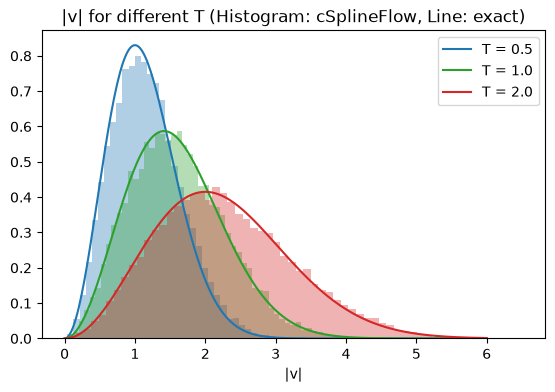

 T  | σ_samples/σ_exact | KS-Distance | KL(p || q)
0.5 |             1.042 |       0.035 | 0.0268
1.0 |             1.008 |       0.011 | 0.0147
2.0 |             1.012 |       0.016 | 0.0524


In [9]:
temps = np.array([[0.5], [1.0], [2.0]], dtype="float32")
samples_T = csplineflow.sample(20_000, cond=temps).numpy()
print("cond:", temps.shape, "-> samples:", samples_T.shape)

fig, ax = plt.subplots(figsize=(6.5, 4))
vs = np.linspace(0, 6, 300)
rows = []
for T, s, color in zip(temps[:, 0], samples_T, ["tab:blue", "tab:green", "tab:red"]):
    sp = np.linalg.norm(s, axis=1)
    exact = stats.maxwell(scale=np.sqrt(T))
    ax.hist(sp, bins=60, density=True, alpha=0.35, color=color)
    ax.plot(vs, exact.pdf(vs), color=color, label=f"T = {T:.1f}")

    # KL(p || q) for this temperature from fresh exact samples
    v_T = (rng.standard_normal((10_000, 3)) * np.sqrt(T)).astype("float32")
    logp = -0.5 * (v_T**2).sum(axis=1) / T - 1.5 * np.log(2 * np.pi * T)
    logq = csplineflow.log_prob(v_T, np.full((len(v_T), 1), T, dtype="float32")).numpy()
    rows.append((T, s.std(0).mean() / np.sqrt(T), ks_statistic(sp, exact.cdf), kl_estimate(logp, logq)))
ax.set(title="|v| for different T (Histogram: cSplineFlow, Line: exact)", xlabel="|v|")
ax.legend()
plt.show()

print(" T  | σ_samples/σ_exact | KS-Distance | KL(p || q)")
for T, ratio, ks, kl in rows:
    print(f"{T:.1f} | {ratio:17.3f} | {ks:11.3f} | {kl:.4f}")

**Observation:** One conditional spline flow covers all temperatures: the width scales with `√T` within about 4 % and the KS distances are 0.01–0.035. The KL values (0.015–0.05) are somewhat higher than with cRealNVP (0.01–0.02), mostly at `T = 2`, where the distribution is widest. As before, the largest relative width error occurs at the edge of the training range (`T = 0.5`). Longer training or a tuned model can most likely reduce these deviations.

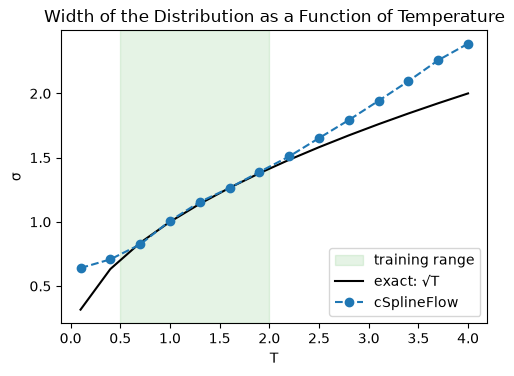

In [10]:
# Scaling of the standard deviation inside and outside the training range [0.5, 2]
T_grid = np.linspace(0.1, 4.0, 14, dtype="float32")[:, None]
s_grid = csplineflow.sample(5000, cond=T_grid).numpy()          # (14, 5000, 3)
sigma_model = s_grid.std(axis=1).mean(axis=1)

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.axvspan(0.5, 2.0, color="tab:green", alpha=0.12, label="training range")
ax.plot(T_grid[:, 0], np.sqrt(T_grid[:, 0]), "k", label="exact: √T")
ax.plot(T_grid[:, 0], sigma_model, "o--", label="cSplineFlow")
ax.set(title="Width of the Distribution as a Function of Temperature", xlabel="T", ylabel="σ")
ax.legend()
plt.show()

**Observation:** Inside the training range the width follows `√T` closely. Outside the range the spline flow, like cRealNVP, **does not extrapolate** correctly: it is twice too wide at `T = 0.1` (σ ≈ 0.64 instead of 0.32) and about 20 % too wide at `T = 4`. A conditional flow is only reliable where there is training data for the condition; physical constraints (such as the DB loss) can help beyond it.

## 6. Influence of the number of coupling layers `n_coupling` and of the number of bins `n_bins`

A single coupling layer transforms only part of the dimensions, so at least two layers are needed in 2D to transform every
component. In contrast to RealNVP, a single spline layer can already create several modes, so the mixture of Section 3 should
need fewer layers than with affine coupling (RealNVP needed 4). The second knob is the number of spline bins `n_bins`, the
flexibility of every single spline.


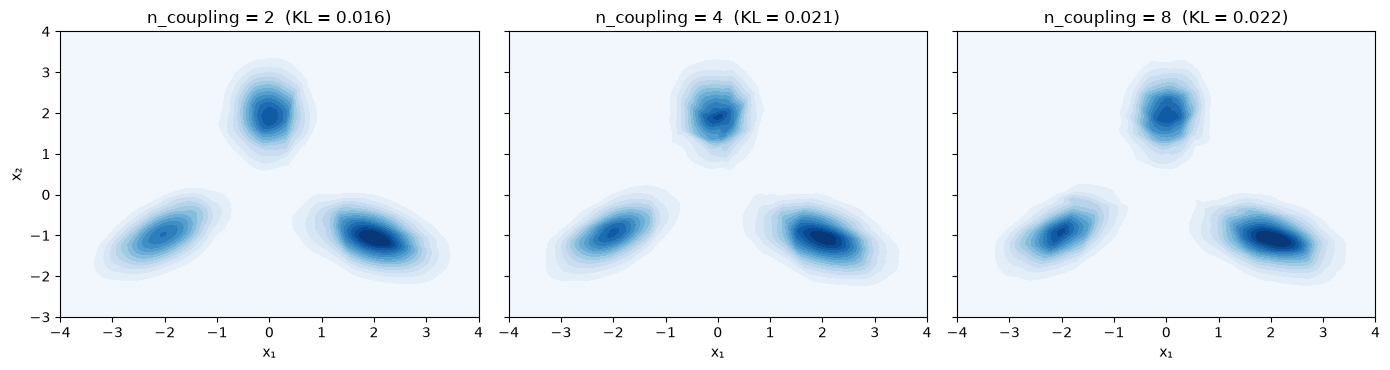

n_coupling | KL(p || q) | KS(x₁)
         2 |     0.0158 | 0.016
         4 |     0.0215 | 0.011
         8 |     0.0220 | 0.014


In [11]:
sweep = {}
for nc in [2, 4, 8]:
    tf.keras.utils.set_random_seed(0)
    m = build_model("splineflow", x_dim=2, n_coupling=nc)
    fit_model(m, x_gm, epochs=60, **FIT)
    logq = m.log_prob(x_gm_test).numpy()
    dens = np.exp(m.log_prob(xy_grid).numpy()).reshape(gx.shape)
    s = m.sample(10_000).numpy()
    sweep[nc] = dict(kl=kl_estimate(mixture_logpdf(x_gm_test), logq), ks=ks_statistic(s[:, 0], mixture_marginal_cdf), dens=dens)

fig, axes = plt.subplots(1, len(sweep), figsize=(14, 3.8), sharey=True)
for ax, (nc, r) in zip(axes, sweep.items()):
    ax.contourf(gx, gy, np.minimum(r["dens"], levels[-1]), levels=levels, cmap="Blues")
    ax.set(title=f"n_coupling = {nc}  (KL = {r['kl']:.3f})", xlabel="x₁")
axes[0].set_ylabel("x₂")
fig.tight_layout()
plt.show()

print("n_coupling | KL(p || q) | KS(x₁)")
for nc, r in sweep.items():
    print(f"{nc:10d} | {r['kl']:10.4f} | {r['ks']:.3f}")


**Observation:** Already **2 coupling layers** (every dimension transformed once) fit the mixture well (KL ≈ 0.016), whereas RealNVP with 2 layers could not separate the components (KL ≈ 0.25). More layers bring no gain at this training length (KL ≈ 0.02 for 4 and 8 layers; the differences are within run-to-run variation), and the contours become slightly bumpier. This is the main advantage of spline coupling: each layer is much more expressive, so fewer layers are needed.

### Number of bins

With the smallest number of coupling layers (`n_coupling = 2`, every dimension is transformed exactly once) the flexibility
comes from the splines alone. More bins allow sharper bends of the transformation.


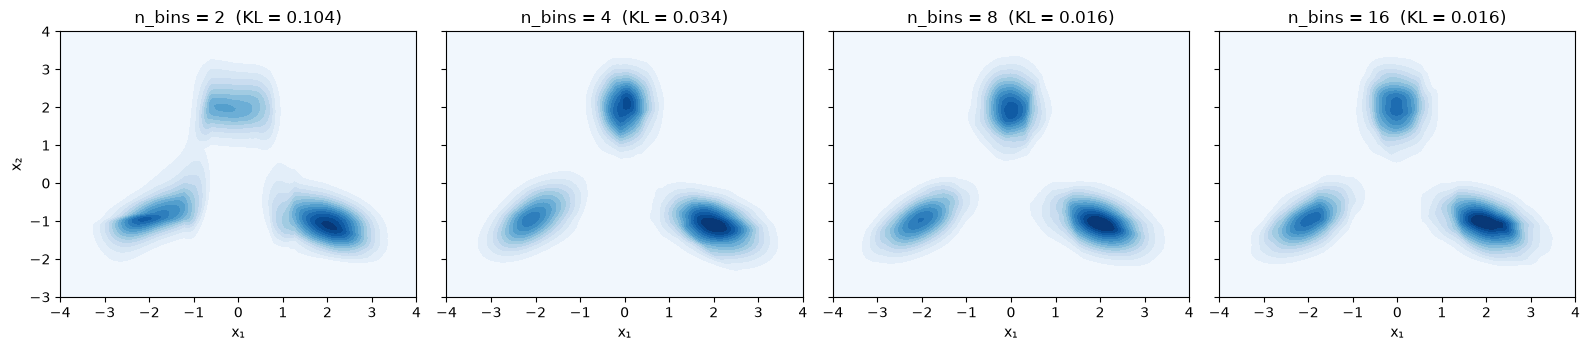

n_bins | KL(p || q)
     2 |     0.1039
     4 |     0.0340
     8 |     0.0158
    16 |     0.0158


In [12]:
sweep_bins = {}
for nb in [2, 4, 8, 16]:
    tf.keras.utils.set_random_seed(0)
    m = build_model("splineflow", x_dim=2, n_coupling=2, n_bins=nb)
    fit_model(m, x_gm, epochs=60, **FIT)
    logq = m.log_prob(x_gm_test).numpy()
    dens = np.exp(m.log_prob(xy_grid).numpy()).reshape(gx.shape)
    sweep_bins[nb] = dict(kl=kl_estimate(mixture_logpdf(x_gm_test), logq), dens=dens)

fig, axes = plt.subplots(1, len(sweep_bins), figsize=(16, 3.6), sharey=True)
for ax, (nb, r) in zip(axes, sweep_bins.items()):
    ax.contourf(gx, gy, np.minimum(r["dens"], levels[-1]), levels=levels, cmap="Blues")
    ax.set(title=f"n_bins = {nb}  (KL = {r['kl']:.3f})", xlabel="x₁")
axes[0].set_ylabel("x₂")
fig.tight_layout()
plt.show()

print("n_bins | KL(p || q)")
for nb, r in sweep_bins.items():
    print(f"{nb:6d} | {r['kl']:10.4f}")


**Observation:** With only 2 bins the spline is not flexible enough: the components are distorted and connected by a visible bridge (KL ≈ 0.10). 4 bins already separate the modes (KL ≈ 0.034), and 8 bins (the default) reach KL ≈ 0.016. 16 bins give no further gain for this smooth target.

## 7. Invertibility, Storage and Loading

A normalizing flow is a bijection: `forward` maps data to the latent space (a standard normal), `inverse` maps back.
Both directions share the same weights, and `log_prob = log N(z) + log|det J|`.

In [13]:
z, log_det = csplineflow.forward(v_train[:2000], T_train[:2000])
v_back = csplineflow.inverse(z, T_train[:2000]).numpy()

print("max. reconstruction error |inverse(forward(v)) - v|:", float(np.abs(v_back - v_train[:2000]).max()))
print("latent variables z (should be ~ N(0, 1)): mean", z.numpy().mean(0).round(3), "| std", z.numpy().std(0).round(3))

max. reconstruction error |inverse(forward(v)) - v|: 4.0531158447265625e-06
latent variables z (should be ~ N(0, 1)): mean [ 0.053 -0.022 -0.045] | std [0.986 1.015 0.962]


**Observation:** The inverse reproduces the data up to float precision (≈ 4e-6; the inverse of the rational-quadratic spline solves a quadratic equation, which costs a little precision compared with an affine layer), and the latent variables are close to standard normal, which confirms a consistent forward/inverse pair and a correctly trained flow.

To load the model, a model with **the same architecture** is built and initialized with `warmup()`
(`warmup()` sets all weights without training anything).

In [14]:
path = Path(tempfile.mkdtemp()) / "csplineflow_maxwell.weights.h5"

csplineflow.warmup()
csplineflow.save_weights(str(path))

restored = build_model("csplineflow", x_dim=3, cond_dim=1)
restored.warmup()
restored.load_weights(str(path))

same = all(np.allclose(a, b) for a, b in zip(csplineflow.get_weights(), restored.get_weights()))
print("Weights identical:", same)

Weights identical: True
